# Example: A Rule Switch in a Wolfram Market
In this example, we simulate the Wolfram market, an agent-based model in which interior traders on a grid act on the intentions of their four neighbors. We change one entry of the rule that a fraction of the interior traders follow, and watch the grid and the share price.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Watch a rule switch spread:__ Run a switched market and its control, and use the grid at several steps to say where the Sell intention starts and how it spreads.
> * __Explain the path of the share price:__ Compare the share price of the switched market with its control, and use the filled and unfilled orders to explain why the price stops falling.
> * __Find the fraction of traders that must switch:__ Use cached runs of many starting markets to find the fraction of switching traders at which a Sell majority forms.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/).

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
Tasks 1 and 2 run live. Task 3 uses cached runs from the script `scripts/Compute-L12b-RuleSwitch-Cache.jl`, which ran switched markets and their controls for 20 starting markets, six fractions of switching traders, and three market conditions.

We load the cached runs into the `sweep::DataFrame` variable, with one row for each run:

In [2]:
sweep = let

    # load the cache file, and take its settings and its table of runs -
    path = joinpath(_PATH_TO_DATA, "L12b-RuleSwitch-Cache.jld2");
    d = load(path);
    s = d["settings"]; # how the cache was built
    df = d["sweep"]; # one row for each market condition, fraction f, and starting market

    # show what the cache holds -
    println("cached runs: $(nrow(df)); grid size L = $(s.L); starting markets: $(length(s.seeds)); fractions f: $(join(s.f_values, ", "))");
    println("time step of the cached runs: Δt = 1/$(round(Int, 1/s.Δt)) years; volatility of the dealer noise: σ_S = $(s.σ_S)");

    # checks -
    @assert s.provisional == false "the cache must be the full run, not a quick test run"
    @assert nrow(df) > 0 "the cache must not be empty"

    # return -
    df
end;

cached runs: 360; grid size L = 64; starting markets: 20; fractions f: 0.1, 0.14, 0.16, 0.18, 0.2, 0.25
time step of the cached runs: Δt = 1/98280 years; volatility of the dealer noise: σ_S = 0.2


### Constants
Next, let's set the constants. The live market uses a deep dealer and active edge traders, who buy when the share price is well below its recent average and sell when it is well above it.

Each step lasts `Δt` years, and the default is one minute of trading. At each step, the dealer's share price also changes by a random amount, the __noise__, with annualized volatility `σ_S`. The noise added in one step has standard deviation $\sigma_{S}\sqrt{\Delta t}$, and a longer step gets more noise.

Change the parameters and run the cells again. Tasks 1 and 2 run live and follow the constants. Task 3 uses cached runs, which do not change:

In [3]:
# the live market -
L = 64; # grid size (L × L traders, including the edge)
f = 0.25; # fraction of interior traders that switch to Rule 19286
h = 100.0; # dealer depth; a small value (for example 1.0) makes the price move a long way for a given net order
boundary_mode = :endogenous; # edge traders: :endogenous (active), :hold (held), or :random (random draws)
random_probabilities = (1/3, 1/3, 1/3); # probabilities of (Buy, Hold, Sell) for :random edge traders; ignored otherwise
seed = 1; # starting market; each seed gives a different random start
t_pre = 1000; # steps before the switch
t_post = 3000; # steps after the switch
snapshot_every = 5; # we save the grid every 5 steps

# the time step and the noise in the dealer's share price -
Δt = 1/(252*390); # length of one step (years), one minute of a 390-minute trading day
σ_S = 0.20; # annualized volatility of the noise in the dealer's share price (1/√yr); the noise added in one step has standard deviation σ_S√Δt, and 0.0 gives no noise

# the starting markets in Task 2 -
L_small = 32; # a smaller grid, so that 20 markets run in a few seconds
seeds = 1:20; # the starting markets

# the market conditions in the cached runs of Task 3, and how we name them in the plots -
conditions = ["h=100.0/endogenous", "h=100.0/hold", "h=1.0/endogenous"]; # labels stored in the cache
condition_names = ["deep dealer, active edge", "deep dealer, held edge", "shallow dealer, active edge"];
condition_colors = [:red, :deepskyblue1, :green4];

# colors used in every plot -
color_switched = :red; # the switched market
color_control = :navy; # the control market, which never switches
intention_colors = [parse(Colorant, "#0072B2"), parse(Colorant, "#AAAAAA"), parse(Colorant, "#D55E00")]; # Buy is blue, Hold is gray, Sell is orange

___

## Task 1: Watch a Rule Switch Spread
In this task, we run a switched market and its control, and watch the Sell intention spread across the grid.

In a __rule switch__, all interior traders follow Rule 19280 until the switch step, and then a fraction $f$ of them change to Rule 19286. The two rules differ in one entry: a trader with three Buy neighbors and one Hold neighbor buys under Rule 19280 and sells under Rule 19286. The __control__ shares the history of the switched market and never switches.

The `run_noisy_rule_switch(...)` function in `src/Helper.jl` runs both markets with the same dealer noise, and saves the grid at the steps we pass in `snapshot_steps`. We store the two markets and the saved steps in the `live::NamedTuple` variable:

In [4]:
live = let

    # initialize: the steps at which we save the grid -
    saved_steps = collect(0:snapshot_every:(t_pre + t_post));

    # the random-edge probabilities only matter for :random edge traders -
    kw = NamedTuple();
    if boundary_mode == :random
        kw = (random_edge_probabilities = random_probabilities,);
    end

    # run the switched market and its control, and time it -
    t_run = @elapsed pair = run_noisy_rule_switch(; L = L, f = f, h = h, seed = seed, boundary_mode = boundary_mode,
        σ_S = σ_S, Δt = Δt, t_pre = t_pre, t_post = t_post, snapshot_steps = saved_steps, kw...);
    println("run time: $(round(t_run; digits = 1)) seconds; saved grids: $(length(saved_steps))");

    # checks -
    @assert t_pre % snapshot_every == 0 "the switch step must be a saved step"
    @assert pair.switched.frames[t_pre] == pair.control.frames[t_pre] "switched and control must share their history"
    @assert length(pair.switched.prices) == t_pre + t_post + 1 "one price for each step, including step 0"

    # return -
    (switched = pair.switched, control = pair.control, saved_steps = saved_steps)
end;

run time: 1.8 seconds; saved grids: 801


Let's look at the grid at six steps, from the switch step to the last step. Each tile is one interior trader: Buy is blue, Hold is gray, and Sell is orange. The top row shows the control, and the bottom row shows the switched market at the same steps:

In [5]:
steps_to_visualize = [1000, 1100, 1200, 1300, 1500, 4000]; # six saved steps, in order

`Unhide` the code block below to see how we drew the grids with the `plot_grid(...)` helper in `src/Helper.jl`.

Where does the Sell intention start?

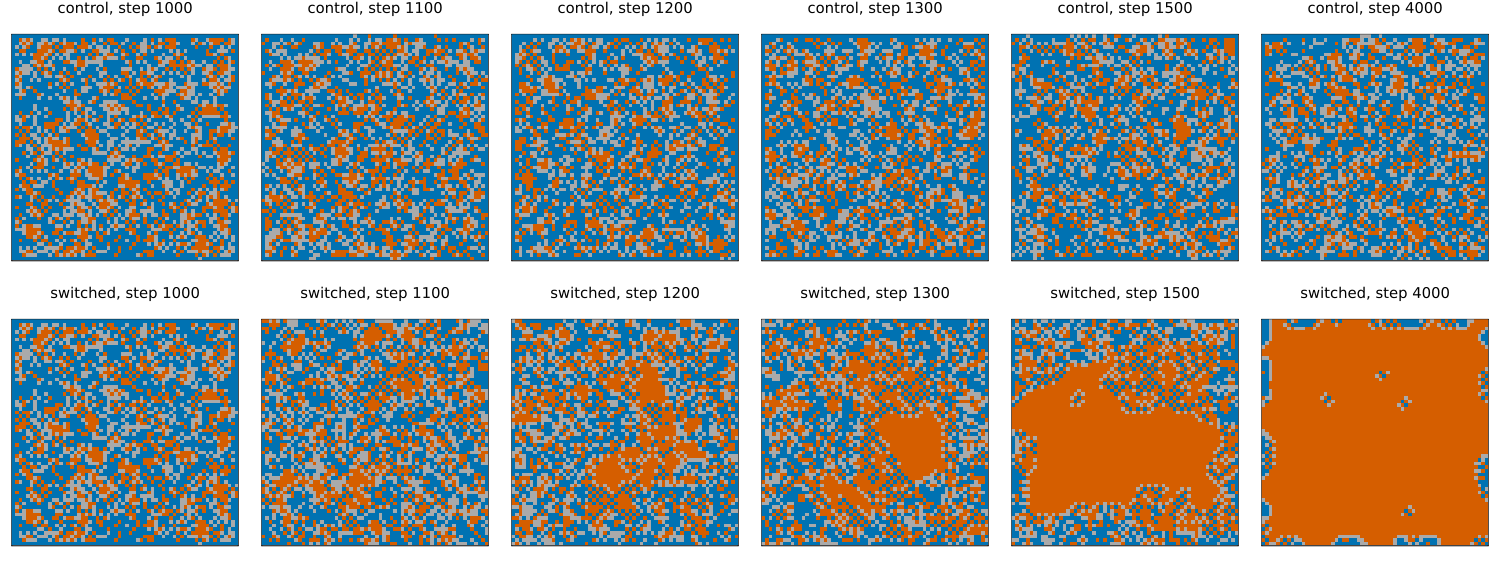

In [6]:
let

    # draw the top row: the control at each step -
    panels = [];
    for t ∈ steps_to_visualize
        push!(panels, plot_grid(live.control.frames[t]; colors = intention_colors, title_text = "control, step $(t)"));
    end

    # draw the bottom row: the switched market at the same steps -
    for t ∈ steps_to_visualize
        push!(panels, plot_grid(live.switched.frames[t]; colors = intention_colors, title_text = "switched, step $(t)"));
    end

    # show the two rows: the layout fills the top row first -
    number_of_steps = length(steps_to_visualize);
    plot(panels..., layout = (2, number_of_steps), size = (250*number_of_steps, 570), margin = 1Plots.mm)
end

> __What do we see?__
>
> * __The switch step:__ At step 1,000, the two markets have the same grid. The three intentions are mixed, and about one trader in four intends to sell.
> * __One region grows:__ By step 1,300, a solid region of Sell has formed in the switched market. It grows outward from step to step, and by step 1,500 it covers about half of the grid.
> * __The last step:__ Sell fills the switched grid except for a band of traders near the edge and a few small clusters. The control stays mixed at every step.

Next, let's watch the two grids and the share price together. `Unhide` the code block below to see how we built the animation, which draws one frame every 20 steps with [the @animate macro](https://docs.juliaplots.org/stable/animations/):

Plots.AnimatedGif("/var/folders/82/m7j29m517p9c2201mdkk3m580000gp/T/jl_H4xYVWp67C.gif")
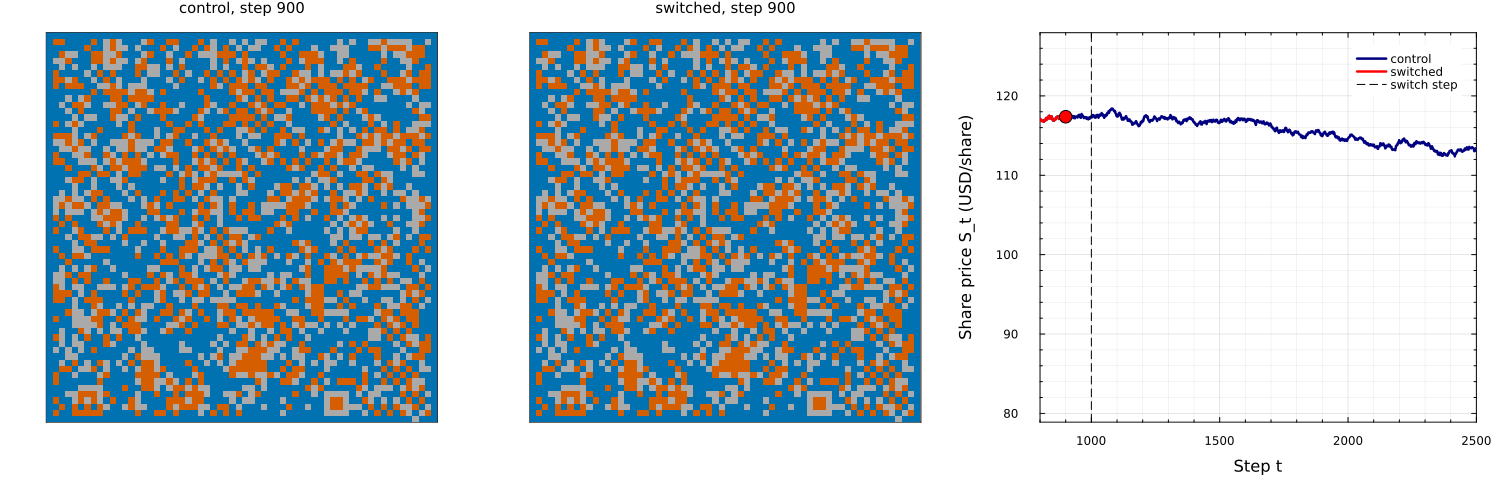

In [7]:
let

    # initialize: the steps we draw, from 100 steps before the switch to 1,400 steps after it -
    animation_steps = [t for t ∈ live.saved_steps if (t_pre - 100 <= t <= t_pre + 1400) && (t % 20 == 0)];
    all_steps = 0:(t_pre + t_post); # step numbers of the prices
    y_low = 0.95*minimum(live.switched.prices); # price axis limits, shared by every frame
    y_high = 1.08*maximum(live.switched.prices);

    # draw one frame for each step: the control grid, the switched grid, and the share price up to that step -
    animation = @animate for t ∈ animation_steps

        # left and center: the grids of the control and of the switched market -
        p_control = plot_grid(live.control.frames[t]; colors = intention_colors, title_text = "control, step $(t)");
        p_switched = plot_grid(live.switched.frames[t]; colors = intention_colors, title_text = "switched, step $(t)");

        # right: the control price, and the switched price up to step t -
        p_price = plot(all_steps, live.control.prices, lw = 2.5, c = color_control, label = "control",
            bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, xlims = (t_pre - 200, t_pre + 1500), ylims = (y_low, y_high), legend = :topright);
        plot!(p_price, 0:t, live.switched.prices[1:(t + 1)], lw = 2.5, c = color_switched, label = "switched");
        scatter!(p_price, [t], [live.switched.prices[t + 1]], ms = 7, c = color_switched, label = "");
        vline!(p_price, [t_pre], lw = 1, c = :black, ls = :dash, label = "switch step");
        xlabel!(p_price, "Step t", fontsize = 18);
        ylabel!(p_price, "Share price S_t (USD/share)", fontsize = 18);

        plot(p_control, p_switched, p_price, layout = (1, 3), size = (1500, 490), margin = 4Plots.mm, bottom_margin = 9Plots.mm)
    end

    # show the animation at 12 frames per second -
    gif(animation, tempname() * ".gif"; fps = 12, show_msg = false)
end

The two markets share every step up to the switch, and only the switched market forms a Sell region. Your grids will differ if you change the parameters, because each `seed` gives a different starting market.

___

## Task 2: Follow the Share Price
In this task, we compare the share price of the switched market with its control, and ask why the price stops falling.

The dealer quotes the share price from its cash and shares. Net selling lowers the price, and net buying raises it. The __Sell fraction__ is the fraction of interior traders who intend to sell, and a market has a __Sell majority__ once the Sell fraction reaches one half after the switch.

`Unhide` the code block below to see how we plotted the Sell fraction and the share price of the two markets from Task 1.

Does the share price follow the Sell fraction?

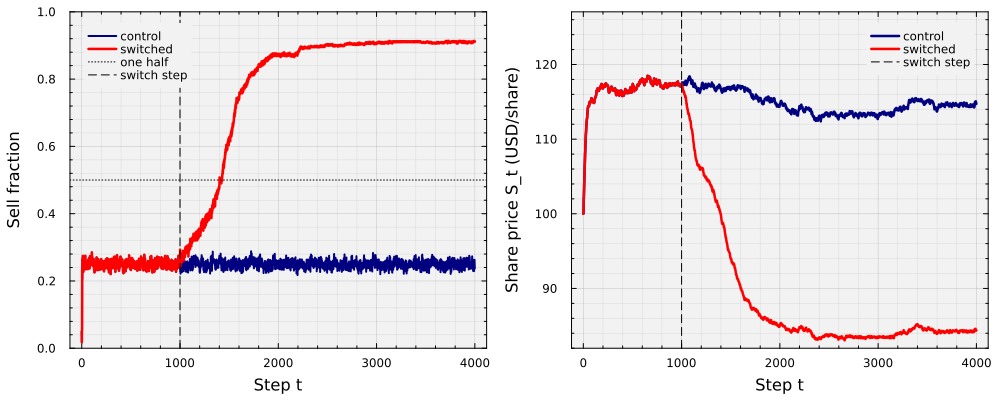

In [8]:
let

    # initialize: the step numbers -
    all_steps = 0:(t_pre + t_post);

    # left panel: the fraction of interior traders who intend to sell -
    p_sell = plot(all_steps, live.control.sell_fraction, lw = 2, c = color_control, label = "control",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, ylims = (0.0, 1.0), legend = :topleft);
    plot!(p_sell, all_steps, live.switched.sell_fraction, lw = 2.5, c = color_switched, label = "switched");
    hline!(p_sell, [0.5], lw = 1, c = :black, ls = :dot, label = "one half");
    vline!(p_sell, [t_pre], lw = 1, c = :black, ls = :dash, label = "switch step");
    xlabel!(p_sell, "Step t", fontsize = 18);
    ylabel!(p_sell, "Sell fraction", fontsize = 18);

    # right panel: the share price that the dealer quotes -
    p_price = plot(all_steps, live.control.prices, lw = 2.5, c = color_control, label = "control",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :topright);
    plot!(p_price, all_steps, live.switched.prices, lw = 2.5, c = color_switched, label = "switched");
    vline!(p_price, [t_pre], lw = 1, c = :black, ls = :dash, label = "switch step");
    (y_low, y_high) = ylims(p_price);
    ylims!(p_price, y_low, y_high + 0.2*(y_high - y_low)); # leave room for the legend
    xlabel!(p_price, "Step t", fontsize = 18);
    ylabel!(p_price, "Share price S_t (USD/share)", fontsize = 18);

    # show the two panels side by side -
    plot(p_sell, p_price, layout = (1, 2), size = (1000, 400), bottom_margin = 5Plots.mm, left_margin = 5Plots.mm)
end

> __What do we see?__
>
> * __Sell fraction:__ The Sell fraction of the switched market crosses one half about 400 steps after the switch and levels off near 0.91. At one minute per step, 400 steps is about one trading day. The control stays near 0.25.
> * __Share price:__ The switched price falls from about 117 to about 85 USD/share in the first 1,000 steps after the switch. It then stays near 84 USD/share while the Sell fraction stays high. The control price moves with the noise and stays between 112 and 119 USD/share.

About nine traders in ten intend to sell, and the share price has stopped falling. A trader can sell only the shares it holds, and each trader started with `10` shares.

`Unhide` the code block below to see how we plotted the orders in the switched market at each step: the Sell and Buy orders that the dealer filled, and the Sell orders that failed because the trader had no shares.

Why does the share price stop falling?

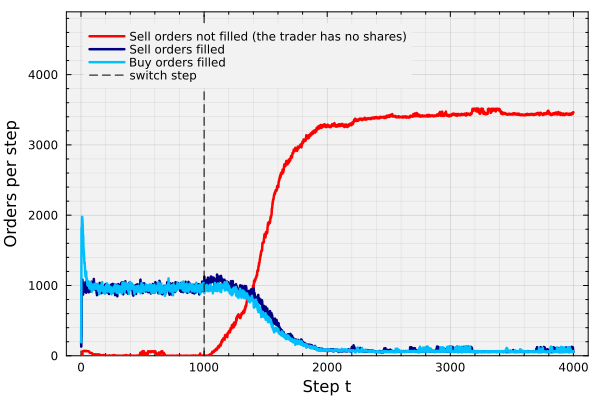

In [9]:
let

    # initialize: one count for each step after step 0 -
    steps_with_orders = 1:(t_pre + t_post);
    market = live.switched;

    # plot: unfilled Sell orders, filled Sell orders, and filled Buy orders -
    q = plot(steps_with_orders, market.suppressed_sells, lw = 2.5, c = :red, label = "Sell orders not filled (the trader has no shares)",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :topleft);
    plot!(q, steps_with_orders, market.executed_sells, lw = 2.5, c = :navy, label = "Sell orders filled");
    plot!(q, steps_with_orders, market.executed_buys, lw = 2.5, c = :deepskyblue1, label = "Buy orders filled");
    vline!(q, [t_pre], lw = 1, c = :black, ls = :dash, label = "switch step");

    # labels: leave room for the legend at the top of the axes -
    ylims!(q, 0, 1.35*ylims(q)[2]);
    xlabel!(q, "Step t", fontsize = 18);
    ylabel!(q, "Orders per step", fontsize = 18)
end

> __What do we see?__
>
> * __Before the switch:__ The dealer fills about 970 Sell orders and as many Buy orders at each step, and almost no Sell order fails.
> * __After the switch:__ The filled Sell orders rise for about 100 steps, then fall to about 70 per step as the sellers run out of shares. About 3,400 Sell orders fail at each step.
> * __The price levels off:__ Late in the run, the filled Sell orders and the filled Buy orders are about equal. The net trade is close to zero, and only the noise moves the dealer's price.

One market is one starting market. Let's repeat the switch for 20 starting markets on a smaller grid, with the same parameters. We store the share prices of each switched market and its control in the `markets::Vector{NamedTuple}` variable:

In [10]:
markets = let

    # initialize: one entry for each starting market -
    results = NamedTuple[];

    # the random-edge probabilities only matter for :random edge traders -
    kw = NamedTuple();
    if boundary_mode == :random
        kw = (random_edge_probabilities = random_probabilities,);
    end

    # main loop: run the switched market and its control for each seed -
    t_run = @elapsed for s ∈ seeds
        pair = run_noisy_rule_switch(; L = L_small, f = f, h = h, seed = s, boundary_mode = boundary_mode, σ_S = σ_S, Δt = Δt, t_pre = t_pre, t_post = t_post, kw...);
        push!(results, (seed = s, switched = pair.switched.prices, control = pair.control.prices));
    end
    println("run time for $(length(seeds)) starting markets: $(round(t_run; digits = 1)) seconds");

    # checks -
    @assert length(results) == length(seeds) "one entry for each starting market"

    # return -
    results
end;

run time for 20 starting markets: 2.7 seconds


`Unhide` the code block below to see how we plotted the share price of every switched market and every control.

Do all the starting markets end at the same share price?

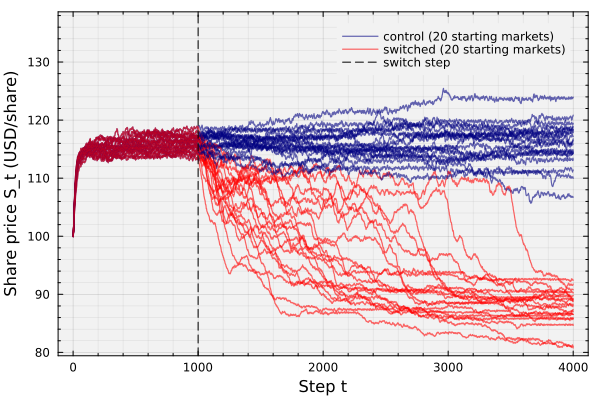

In [11]:
let

    # initialize: the step numbers -
    all_steps = 0:(t_pre + t_post);

    # plot: one thin line for each market; only the first line of each kind gets a legend entry -
    q = plot(bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :topright);
    for m ∈ markets
        label_control = "";
        label_switched = "";
        if m.seed == first(seeds)
            label_control = "control ($(length(seeds)) starting markets)";
            label_switched = "switched ($(length(seeds)) starting markets)";
        end
        plot!(q, all_steps, m.control, lw = 1.2, c = color_control, alpha = 0.6, label = label_control);
        plot!(q, all_steps, m.switched, lw = 1.2, c = color_switched, alpha = 0.6, label = label_switched);
    end
    vline!(q, [t_pre], lw = 1, c = :black, ls = :dash, label = "switch step");

    # labels: leave room for the legend at the top of the axes -
    (y_low, y_high) = ylims(q);
    ylims!(q, y_low, y_high + 0.25*(y_high - y_low));
    xlabel!(q, "Step t", fontsize = 18);
    ylabel!(q, "Share price S_t (USD/share)", fontsize = 18)
end

> __What do we see?__
>
> * __Every switched price falls:__ All 20 switched prices leave the control prices after the switch, and none of them recovers.
> * __Different speeds, one level:__ Some prices fall within 1,000 steps and others take more than 2,000. Most end between 85 and 91 USD/share, the level at which the sellers have run out of shares.

___

## Task 3: How Many Traders Must Switch?
In this task, we use the cached runs to find the fraction of switching traders at which a Sell majority forms.

The cached runs repeat the switch on the larger grid for six values of $f$, 20 starting markets, and three market conditions. We made the cached runs ahead of time with a one-minute step and a noise volatility of `0.20`, and the constants above do not change them.

The edge traders are __active__, or __held__ in Hold at every step. The dealer is __deep__, or __shallow__, which moves the price more for each trade.

For each condition and each $f$, we compute the fraction of starting markets with a Sell majority and the median __fall__ of the share price. The fall is the largest drop of the price from a running peak after the switch, in percent. We store the results in the `threshold::DataFrame` variable:

In [12]:
threshold = let

    # initialize: the fractions in the cache, and one row for each condition and fraction -
    f_values = sort(unique(sweep.f));
    rows = NamedTuple[];

    # main loop: summarize the starting markets of each condition and fraction -
    for c ∈ conditions
        for fraction ∈ f_values
            runs = sweep[(sweep.condition .== c) .& (sweep.f .== fraction), :]; # the starting markets of this case
            push!(rows, (
                condition = c,
                f = fraction,
                fraction_majority = mean(runs.transitioned), # fraction of starting markets with a Sell majority
                median_fall = 100*median(runs.max_drawdown), # switched markets (%)
                median_control_fall = 100*median(runs.control_max_drawdown), # controls (%)
                number_of_markets = nrow(runs)));
        end
    end
    df = DataFrame(rows);

    # checks -
    @assert all(df.number_of_markets .== length(unique(sweep.seed))) "every condition and fraction uses every starting market"
    @assert all(0.0 .<= df.fraction_majority .<= 1.0) "fractions must lie in [0, 1]"
    @assert any(sweep.control_transitioned) == false "no control forms a Sell majority"

    # return -
    df
end;

The last check in the cell above passes: no control forms a Sell majority, in any condition.

`Unhide` the code block below to see how we plotted the fraction of starting markets with a Sell majority against $f$, with one line for each market condition.

How many traders must switch?

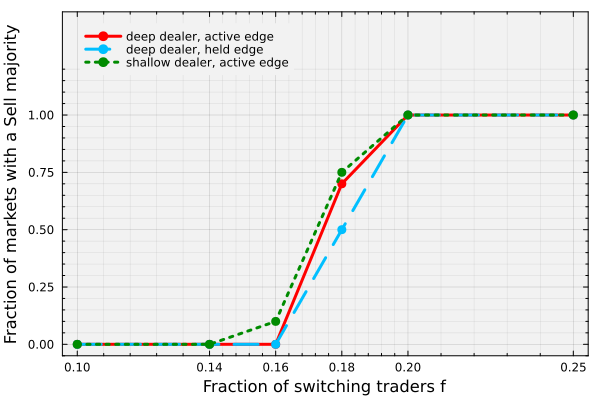

In [13]:
let

    # initialize: the fractions on the horizontal axis, and one line style for each condition -
    f_values = sort(unique(threshold.f));
    line_styles = [:solid, :dash, :dot];

    # plot: one line for each market condition -
    q = plot(bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, ylims = (-0.05, 1.45), yticks = 0:0.25:1, xticks = f_values, legend = :topleft);
    for i ∈ eachindex(conditions)
        rows = threshold[threshold.condition .== conditions[i], :];
        plot!(q, rows.f, rows.fraction_majority, lw = 3, c = condition_colors[i], ls = line_styles[i],
            marker = :circle, ms = 5, markerstrokewidth = 0, label = condition_names[i]);
    end
    xlabel!(q, "Fraction of switching traders f", fontsize = 18);
    ylabel!(q, "Fraction of markets with a Sell majority", fontsize = 18)
end

> __What do we see?__
>
> * __A narrow threshold:__ No starting market forms a Sell majority at $f = 0.14$, and every starting market forms one at $f = 0.20$. At $f = 0.18$, between half and three quarters of them do.
> * __The conditions agree:__ The three lines stay close together. The threshold depends little on the edge traders or on the dealer's depth.

Next, let's look at the fall of the share price for one market condition. Set `condition_to_visualize` to pick the condition:

In [14]:
condition_to_visualize = 1; # 1 = deep dealer, active edge; 2 = deep dealer, held edge; 3 = shallow dealer, active edge

`Unhide` the code block below to see how we plotted the fall of the share price against $f$. Each dot is one starting market, and the lines are the medians of the switched markets and of the controls.

Does the fall of the share price have the same threshold?

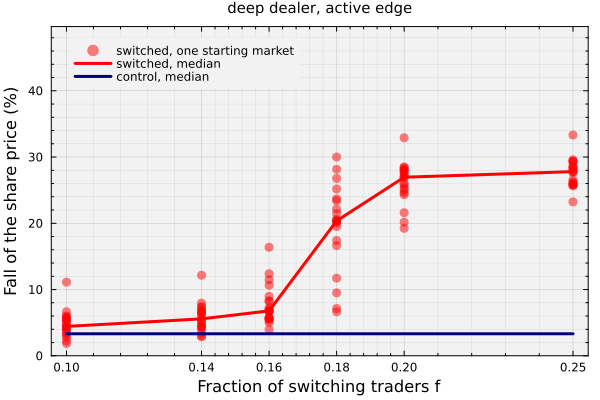

In [15]:
let

    # initialize: the cached runs and the medians of the condition we chose -
    c = conditions[condition_to_visualize];
    runs = sweep[sweep.condition .== c, :];
    rows = threshold[threshold.condition .== c, :];
    f_values = sort(unique(rows.f));

    # plot: one dot for each switched market, then the two medians -
    q = scatter(runs.f, 100 .* runs.max_drawdown, ms = 5, c = color_switched, alpha = 0.5, markerstrokewidth = 0, label = "switched, one starting market",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, xticks = f_values, legend = :topleft);
    plot!(q, rows.f, rows.median_fall, lw = 3, c = color_switched, label = "switched, median");
    plot!(q, rows.f, rows.median_control_fall, lw = 3, c = color_control, label = "control, median");

    # labels: leave room for the legend at the top of the axes -
    ylims!(q, 0, 1.45*ylims(q)[2]);
    xlabel!(q, "Fraction of switching traders f", fontsize = 18);
    ylabel!(q, "Fall of the share price (%)", fontsize = 18);
    title!(q, condition_names[condition_to_visualize], titlefontsize = 10)
end

> __What do we see?__
>
> * __The same threshold:__ With a deep dealer and active edge traders, the median fall is below 7% up to $f = 0.16$ and about 27% from $f = 0.20$. At $f = 0.18$, the starting markets spread between the two.
> * __The control falls little:__ The median fall of the controls is about 3%, which the dealer noise causes. The larger fall of the switched markets comes from the rule switch.
> * __A shallow dealer:__ Set `condition_to_visualize = 3`. The control's price now falls about 33% with no switch, and the switched markets at $f = 0.10$ fall about 39%.

___

## Summary
In this example, we watched a rule switch spread across the grid of a Wolfram market, followed the share price as it fell and leveled off, and found the fraction of switching traders at which a Sell majority forms.

> __Key Takeaways:__
>
> * __The Sell intention spreads from one region:__ We ran a switched market and its control, and saved the grid every five steps. The Sell intention started in one region and spread outward from neighbor to neighbor, while the control stayed mixed.
> * __The share price falls until the sellers run out of shares:__ We compared the share price of the switched market with its control, and counted the filled and unfilled orders. The price fell by more than a quarter and then leveled off, because most traders who intended to sell had no shares left.
> * __A Sell majority needs enough switching traders:__ We used cached runs of 20 starting markets for six fractions of switching traders. No market formed a Sell majority at the small fractions and every market formed one at the large fractions, with a narrow threshold between them.

We can now change the fraction of switching traders, the dealer's depth and noise, the edge traders, the time step, and the starting market, and watch how the grid and the share price respond.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team.

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___